In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from scipy.special import expit

In [2]:
np.random.seed(100)
n = 100
tuition = np.random.normal(1000, 300, n)

z_score = (tuition - tuition.mean()) / tuition.std()
tablet = np.random.binomial(1, expit(z_score)).astype(bool) # expit(x) = 1 / (1 + e^(-x))

enem_score = np.random.normal(200 - 50 * tablet + 0.7 * tuition, 200)
enem_score = (enem_score - enem_score.min()) / (enem_score.max() - enem_score.min())
enem_score *= 1000

data = pd.DataFrame(dict(enem_score=enem_score, Tuition=tuition, Tablet=tablet))

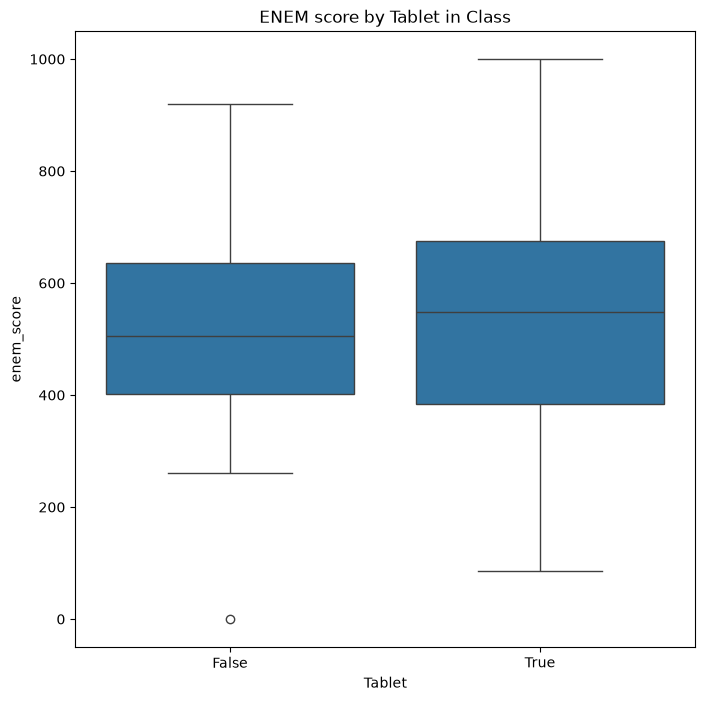

In [3]:
plt.figure(figsize=(8,8))
sns.boxplot(y="enem_score", x="Tablet", data=data).set_title('ENEM score by Tablet in Class')
plt.show()


### CONCLUSION
# even though the students are getting less score after getting tablets, the plot shows otherwise
# this is because the causation between tablets and low scores is negative
# this happened bcz students with higher tution fee are more likely to get tabs here
# and higher tution fee also increases the ENEM score
# so even tho their marks decreased the plot showed boost in their ENEM scores

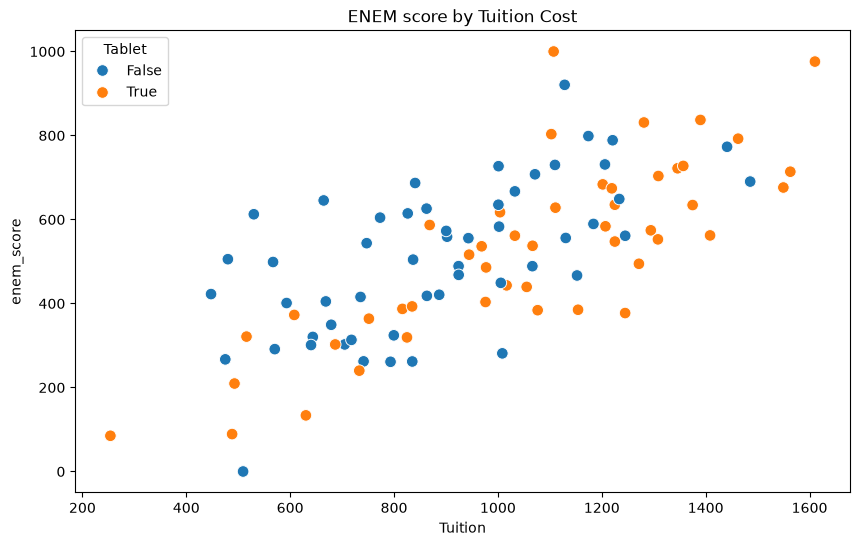

In [4]:
plt.figure(figsize=(10,6))
sns.scatterplot(x="Tuition", y="enem_score", hue="Tablet", data=data, s=70).set_title('ENEM score by Tuition Cost')
plt.show()